# Detecção de fraude em cartão de crédito

Estudo original, em português, para o repositório de Diego. A tarefa é priorizar a transação fraudulenta rara. No arquivo público há 284.807 transações e 492 fraudes, cerca de 0,1727% das linhas. Um classificador que nunca alerta acerta quase todas as linhas e ainda assim deixa passar todas as fraudes. A acurácia, sozinha, não responde à pergunta.

O repositório começou só com o título. Não havia notebook da aula, link da Aula 1 nem código de instrutor. O link da aula do curso na DIO permanece desconhecido e não está confirmado. A fonte pública equivalente adotada aqui é o tutorial oficial do TensorFlow, *Classification on imbalanced data*, e o CSV que esse tutorial hospeda. O arquivo corresponde ao dataset Credit Card Fraud Detection da colaboração Worldline e Machine Learning Group da ULB (Université Libre de Bruxelles), publicado no Kaggle.

O notebook baixa o CSV por URL, sem conta e sem credencial. O arquivo fica em `data/` e o `.gitignore` impede o commit. Não há cartão, nome, documento ou pagamento identificável: `V1`–`V28` já chegaram anonimizados por PCA.


## Proveniência e licença

Conferido nas páginas públicas, em novembro de 2026:

- Tutorial: [Classification on imbalanced data](https://www.tensorflow.org/tutorials/structured_data/imbalanced_data). O código do tutorial é Apache 2.0. A página baixa `https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv` e descreve o arquivo como o dataset do Kaggle coletado pela Worldline e pelo MLG-ULB. A página do tutorial não declara uma licença separada para o CSV.
- Dataset de origem: [Credit Card Fraud Detection](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud), organização Machine Learning Group - ULB. O JSON-LD público da página nomeia a licença como "Database: Open Database, Contents: Database Contents" e aponta [http://opendatacommons.org/licenses/dbcl/1.0/](http://opendatacommons.org/licenses/dbcl/1.0/) (Database Contents License, DbCL 1.0). A mesma página pede a citação de Andrea Dal Pozzolo, Olivier Caelen, Reid A. Johnson e Gianluca Bontempi, *Calibrating Probability with Undersampling for Unbalanced Classification*, Symposium on Computational Intelligence and Data Mining (CIDM), IEEE, 2015, além dos trabalhos relacionados listados no Kaggle.
- O rótulo curto da Kaggle junta "Open Database" e "Database Contents". O URL estruturado publicado na página leva à DbCL 1.0, não ao URL da Open Database License (`http://opendatacommons.org/licenses/odbl/1.0/`). Este estudo registra o texto e o URL que a página publica.

O sha256 esperado do CSV, conferido de novo neste ambiente, é `76274b691b16a6c49d3f159c883398e03ccd6d1ee12d9d8ee38f4b4b98551a89`.

Dal Pozzolo, A., Caelen, O., Johnson, R. A., & Bontempi, G. (2015). Calibrating probability with undersampling for unbalanced classification. In *2015 IEEE Symposium Series on Computational Intelligence* (CIDM).


## Protocolo e objetivo do limiar

A divisão é estratificada e aleatória, com semente 42: cerca de 60% treino, 20% validação e 20% teste. Ela trata as transações como amostras IID deste recorte de dois dias em setembro de 2013. O número descreve separação dentro desse arquivo embaralhado. Ele não mede produção futura, drift nem uma fila real de investigação. `Time` é o segundo desde a primeira transação da janela. O arquivo não traz identificador de cliente nem de cartão, então não há sequência comportamental por pessoa para construir.

Ordem travada antes de olhar o teste:

1. Conferir o arquivo e a contagem de classes.
2. Remover a duplicata exata da linha inteira, preservando a primeira ocorrência. Cópias idênticas em treino e teste repetiriam o mesmo exemplo e inflariam a métrica.
3. Ajustar o `StandardScaler` só no treino. `log1p(Amount)` não estima parâmetro; entra antes da escala porque o valor é assimétrico. O modelo vê `Amount_log1p_z`, não o euro bruto.
4. Treinar regressão logística e floresta com `class_weight` no ajuste, e XGBoost com `scale_pos_weight` igual à razão negativos/positivos do treino.
5. Para cada modelo com ranking, varrer os limiares realizáveis na validação e maximizar o F2 (beta = 2). No empate, fica o maior limiar.
6. Escolher o modelo pelo F2 de validação nesse limiar. Desempate: average precision e, depois, ROC AUC. O teste não entra na escolha.
7. Calcular o teste uma vez, no par modelo–limiar já travado. O corte 0,5 do mesmo modelo e o dummy entram como referência, porque os dois cortes já estavam definidos.
8. SHAP só depois da métrica, em amostra fixa, para explicação.

O F2 é

$$
F_2 = \frac{5 \cdot \mathrm{precisão} \cdot \mathrm{recall}}{4 \cdot \mathrm{precisão} + \mathrm{recall}}.
$$

Recall pesa mais: deixar passar fraude custa mais do que abrir um alerta a mais. A precisão continua na fórmula. Marcar todas as linhas como fraude leva o recall a 1 e a precisão à prevalência, e o F2 desse ponto perde para um corte que concentra os alertas. Os escores com peso de classe ordenam o risco segundo a perda ponderada. Eles não são probabilidade calibrada de fraude, e o corte 0,5 não significa "50% de chance".

Average precision resume a curva precision–recall pela média das precisões ponderada pelo ganho de recall, sem interpolar. A área trapezoidal liga os pontos por retas e pode divergir da average precision. As duas aparecem lado a lado. A recomendação dos autores do dataset aponta a área sob a curva precision–recall; aqui a average precision é o resumo principal, e o trapézio fica explícito para não serem lidos como o mesmo número.

Reamostragem ficou de fora. O desbalanceamento entra pelos pesos, só no treino. Os hiperparâmetros são fixos, sem busca. O tutorial do TensorFlow descarta `Time` e treina uma rede Keras. Este estudo mantém `Time` padronizado e compara logística, floresta e XGBoost. Transações com valor zero permanecem: retirá-las mudaria a população publicada.


In [1]:
%matplotlib inline

import json
import platform
import sys
import time
import urllib.request
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import sklearn
import xgboost
from IPython.display import display
from matplotlib.patches import Rectangle
from scipy.special import expit
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, precision_recall_curve, roc_curve
from xgboost import XGBClassifier

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir() and (ROOT.parent / "src").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src").is_dir():
    raise RuntimeError(f"Raiz do projeto não encontrada a partir de {Path.cwd()}")
sys.path.insert(0, str(ROOT))

from src.fraude_cartao import (
    BETA_F,
    NOMES_MODELO,
    SHA256_ARQUIVO_PUBLICO,
    URL_CSV_PUBLICO,
    ajustar_atributos,
    amostra_explicacao,
    escolher_limiar_fbeta,
    fingerprint_tabela,
    indice_representativo,
    metricas_operacao,
    preparar_particoes,
    scale_pos_weight_treino,
    sha256_arquivo,
    varrer_limiares,
    contagens_classe,
    conferir_arquivo_bruto,
    SEMENTE_PADRAO,
)

SEMENTE = SEMENTE_PADRAO
CAMINHO = ROOT / "data" / "creditcard.csv"
FIGURAS = ROOT / "artifacts" / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)

CORES = {
    "fundo": "#F3EFE4",
    "tinta": "#1E2430",
    "fraude": "#9E2A3A",
    "legitima": "#1D6A5A",
    "alerta": "#C48A1A",
    "azul": "#2C4A6E",
    "grade": "#E4D9C6",
    "painel": "#FFFDF8",
    "apoio": "#6E675C",
}
plt.rcParams.update(
    {
        "figure.facecolor": CORES["fundo"],
        "axes.facecolor": CORES["painel"],
        "axes.edgecolor": "#D9D0C2",
        "axes.labelcolor": CORES["tinta"],
        "axes.titlecolor": CORES["tinta"],
        "xtick.color": CORES["tinta"],
        "ytick.color": CORES["tinta"],
        "text.color": CORES["tinta"],
        "axes.titleweight": "bold",
        "axes.titlesize": 13,
        "axes.labelsize": 11,
        "font.size": 11,
        "axes.grid": True,
        "grid.color": CORES["grade"],
        "grid.linewidth": 0.7,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "figure.dpi": 120,
        "savefig.dpi": 150,
        "font.family": "DejaVu Sans",
    }
)

NOMES = {
    "dummy_sempre_legitima": "Dummy sempre legítima",
    "regressao_logistica": "Regressão logística",
    "floresta_aleatoria": "Floresta aleatória",
    "xgboost": "XGBoost",
}
CORES_MODELO = {
    "regressao_logistica": CORES["azul"],
    "floresta_aleatoria": CORES["legitima"],
    "xgboost": CORES["fraude"],
}


def salvar(fig, nome):
    try:
        fig.tight_layout()
    except ValueError:
        pass
    caminho = FIGURAS / nome
    fig.savefig(caminho, bbox_inches="tight", facecolor=fig.get_facecolor())
    plt.show()
    return caminho


def escore_positivo(modelo, atributos):
    classes = list(modelo.classes_)
    return modelo.predict_proba(atributos)[:, classes.index(1)]


def jsonavel(valor):
    if isinstance(valor, dict):
        return {str(chave): jsonavel(item) for chave, item in valor.items()}
    if isinstance(valor, (list, tuple)):
        return [jsonavel(item) for item in valor]
    if isinstance(valor, np.ndarray):
        return jsonavel(valor.tolist())
    if isinstance(valor, np.integer):
        return int(valor)
    if isinstance(valor, np.floating):
        return None if np.isnan(valor) else float(valor)
    if isinstance(valor, float) and np.isnan(valor):
        return None
    return valor


versoes = {
    "python": sys.version.split()[0],
    "plataforma": platform.platform(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit-learn": sklearn.__version__,
    "matplotlib": matplotlib.__version__,
    "xgboost": xgboost.__version__,
    "shap": shap.__version__,
}
print(json.dumps(versoes, ensure_ascii=False, indent=2))
print("semente", SEMENTE, "| URL", URL_CSV_PUBLICO)


{
  "python": "3.12.3",
  "plataforma": "Linux-6.12.113+-x86_64-with-glibc2.39",
  "numpy": "2.5.4",
  "pandas": "3.1.1",
  "scikit-learn": "1.9.1",
  "matplotlib": "3.11.2",
  "xgboost": "3.4.1",
  "shap": "0.54.1"
}
semente 42 | URL https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv


## Arquivo, esquema e integridade

A leitura usa o cache local quando o sha256 já confere. Caso contrário, baixa o CSV do espelho do TensorFlow. A célula seguinte imprime esquema, nulos e contagens. Não imprime transações.


In [2]:
def garantir_csv(destino: Path) -> None:
    destino.parent.mkdir(parents=True, exist_ok=True)
    if destino.exists() and sha256_arquivo(destino) == SHA256_ARQUIVO_PUBLICO:
        print("Cache local já confere com o sha256 público.")
        return
    print("Baixando o CSV público.")
    with urllib.request.urlopen(URL_CSV_PUBLICO, timeout=180) as resposta, destino.open("wb") as saida:
        saida.write(resposta.read())
    digest = sha256_arquivo(destino)
    if digest != SHA256_ARQUIVO_PUBLICO:
        destino.unlink(missing_ok=True)
        raise RuntimeError(f"sha256 após o download: {digest}")


garantir_csv(CAMINHO)
relatorio_arquivo = conferir_arquivo_bruto(CAMINHO)
bruto = pd.read_csv(CAMINHO)
fp_tabela_bruta = fingerprint_tabela(bruto)
print(json.dumps({k: v for k, v in relatorio_arquivo.items() if k != "nomes"}, ensure_ascii=False, indent=2))
print("colunas:", ", ".join(relatorio_arquivo["nomes"]))
print(bruto.dtypes.astype(str).value_counts().to_string())
print("sha256 do arquivo:", relatorio_arquivo["sha256"])
print("sha256 canônico da tabela carregada:", fp_tabela_bruta)
print(
    "Amount min/max/zeros:",
    float(bruto["Amount"].min()),
    float(bruto["Amount"].max()),
    int((bruto["Amount"] == 0).sum()),
)
print("Time min/max (segundos):", float(bruto["Time"].min()), float(bruto["Time"].max()))
print(
    "assimetria Amount / log1p(Amount):",
    round(float(bruto["Amount"].skew()), 4),
    round(float(np.log1p(bruto["Amount"]).skew()), 4),
)
print(
    "prevalência bruta:",
    f"{relatorio_arquivo['fraudes'] / relatorio_arquivo['linhas']:.6%}",
)


Cache local já confere com o sha256 público.


{
  "caminho": "/workspace/data/creditcard.csv",
  "sha256": "76274b691b16a6c49d3f159c883398e03ccd6d1ee12d9d8ee38f4b4b98551a89",
  "bytes": 150828752,
  "linhas": 284807,
  "colunas": 31,
  "nulos": 0,
  "normais": 284315,
  "fraudes": 492
}
colunas: Time, V1, V2, V3, V4, V5, V6, V7, V8, V9, V10, V11, V12, V13, V14, V15, V16, V17, V18, V19, V20, V21, V22, V23, V24, V25, V26, V27, V28, Amount, Class
float64    30
int64       1
sha256 do arquivo: 76274b691b16a6c49d3f159c883398e03ccd6d1ee12d9d8ee38f4b4b98551a89
sha256 canônico da tabela carregada: 1700322b377ac8340ab6b75f22b974944fbcaf5b4f0daf3d5e8f620d96313026
Amount min/max/zeros: 0.0 25691.16 1825
Time min/max (segundos): 0.0 172792.0
assimetria Amount / log1p(Amount): 16.9777 0.1627
prevalência bruta: 0.172749%


## Duplicatas exatas, antes do split

Uma linha repetida por inteiro é a mesma transação copiada. Se uma cópia caísse no treino e outra no teste, o teste deixaria de ser novo. A decisão é remover essas cópias antes do sorteio e ficar com a primeira ocorrência do arquivo.

Também conto grupos com os mesmos atributos e rótulos diferentes. Se existirem, o grupo inteiro vai para o treino e fica fora da validação e do teste. No arquivo conferido, esse resto precisa aparecer na conta, seja zero ou não. A sobreposição de atributos entre as três partições é checada em seguida e precisa ser zero.

O fingerprint bruto é o sha256 do arquivo e, em separado, o sha256 do CSV canônico da tabela carregada. O fingerprint pós-limpeza é o sha256 do CSV canônico depois de `drop_duplicates(keep="first")`, na ordem do arquivo. Contagem e hash mudam porque as cópias saíram.


In [3]:
limpo = bruto.drop_duplicates(keep="first").reset_index(drop=True)
fp_tabela_limpa = fingerprint_tabela(limpo)
treino, validacao, teste, relatorio = preparar_particoes(bruto)
del bruto

assert fp_tabela_bruta != fp_tabela_limpa
assert relatorio["linhas_brutas"] != relatorio["linhas_apos_remocao"]
assert relatorio["linhas_apos_remocao"] == len(limpo)
assert relatorio["duplicatas_exatas_extras_depois"] == 0
assert sum(relatorio["sobreposicao_atributos"].values()) == 0
assert relatorio["fraude_depois"] == int(
    treino["Class"].sum() + validacao["Class"].sum() + teste["Class"].sum()
)
del limpo

print(json.dumps(relatorio, ensure_ascii=False, indent=2))
print("sha256 arquivo bruto:      ", SHA256_ARQUIVO_PUBLICO)
print("sha256 tabela carregada:   ", fp_tabela_bruta)
print("sha256 tabela sem cópia:   ", fp_tabela_limpa)
print("linhas brutas / limpas:    ", relatorio["linhas_brutas"], relatorio["linhas_apos_remocao"])

quadro = pd.DataFrame(
    {
        "treino": contagens_classe(treino),
        "validacao": contagens_classe(validacao),
        "teste": contagens_classe(teste),
    }
)
display(quadro)


{
  "linhas_brutas": 284807,
  "duplicatas_exatas_extras": 1081,
  "linhas_em_grupos_duplicados": 1854,
  "grupos_duplicados": 773,
  "duplicatas_de_atributos_extras_antes": 1081,
  "conflitos_de_classe": 0,
  "fraude_antes": 492,
  "normal_antes": 284315,
  "linhas_apos_remocao": 283726,
  "fraude_depois": 473,
  "normal_depois": 283253,
  "duplicatas_exatas_extras_depois": 0,
  "decisao": "remover_duplicata_exata_antes_do_split",
  "criterio_keep": "first",
  "linhas_de_grupos_atributo_forcadas_no_treino": 0,
  "linhas_elegiveis_ao_split": 283726,
  "semente": 42,
  "fracao_teste": 0.2,
  "fracao_validacao_do_restante": 0.25,
  "treino": 170235,
  "validacao": 56745,
  "teste": 56746,
  "sobreposicao_atributos": {
    "treino_validacao": 0,
    "treino_teste": 0,
    "validacao_teste": 0
  }
}
sha256 arquivo bruto:       76274b691b16a6c49d3f159c883398e03ccd6d1ee12d9d8ee38f4b4b98551a89
sha256 tabela carregada:    1700322b377ac8340ab6b75f22b974944fbcaf5b4f0daf3d5e8f620d96313026
sha256 

,treino,validacao,teste
n,170235.000000,56745.000000,56746.000000
normais,169951.000000,56651.000000,56651.000000
fraudes,284.000000,94.000000,95.000000
prevalencia,0.001668,0.001657,0.001674


## O que os gráficos descritivos mostram

As figuras usam a tabela já sem duplicata exata, que é a população do modelo. A hora do relógio junta os dois dias da janela e fica só na descrição: ela não vira coluna do modelo. `Time` entra depois, contínuo e padronizado.


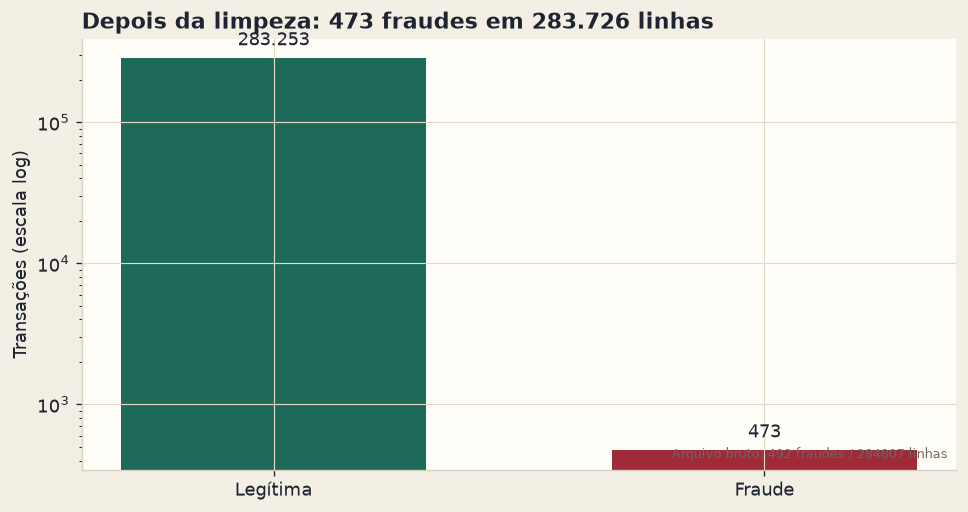

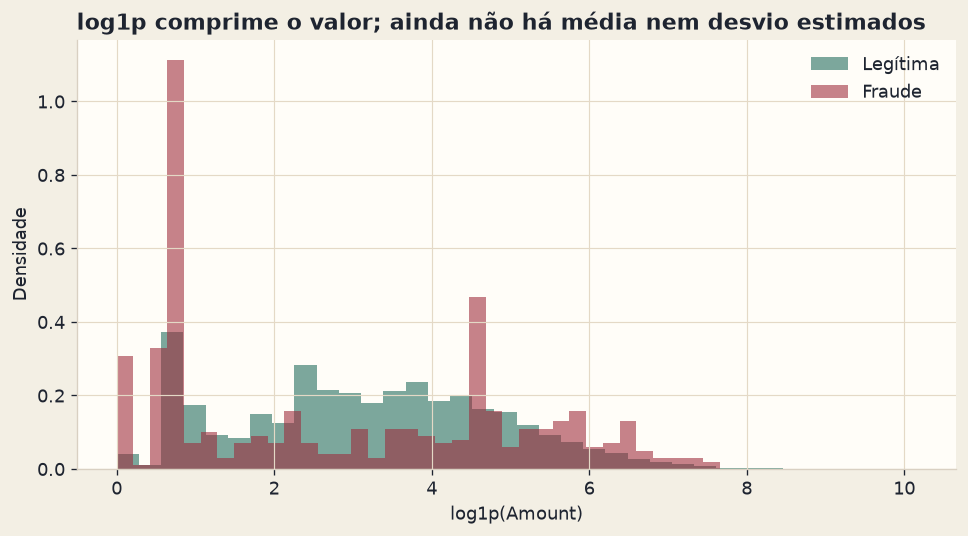

Quantis de Amount na tabela limpa
legítima: n=283253 mediana=22.00 p90=203.00 p99=1018.06 média=88.41 máximo=25691.16
fraude: n=473 mediana=9.82 p90=348.65 p99=1364.14 média=123.87 máximo=2125.87


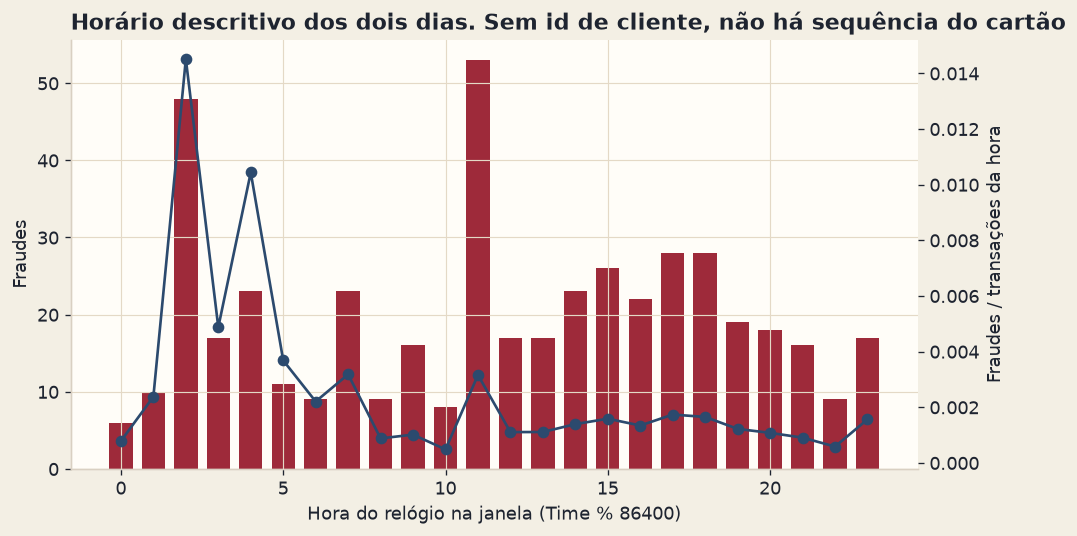

In [4]:
eda = pd.concat([treino, validacao, teste], ignore_index=True)

fig, ax = plt.subplots(figsize=(8.2, 4.4))
contagens = [int((eda["Class"] == 0).sum()), int((eda["Class"] == 1).sum())]
barras = ax.bar(
    ["Legítima", "Fraude"],
    contagens,
    color=[CORES["legitima"], CORES["fraude"]],
    width=0.62,
)
ax.set_yscale("log")
ax.set_ylabel("Transações (escala log)")
ax.set_title(
    f"Depois da limpeza: {contagens[1]} fraudes em {len(eda):,} linhas".replace(",", "."),
    loc="left",
)
for barra, valor in zip(barras, contagens):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        valor * 1.15,
        f"{valor:,}".replace(",", "."),
        ha="center",
        va="bottom",
        fontsize=11,
    )
ax.text(
    0.99,
    0.02,
    f"Arquivo bruto: {relatorio['fraude_antes']} fraudes / {relatorio['linhas_brutas']} linhas",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    color=CORES["apoio"],
    fontsize=8,
)
salvar(fig, "01_desbalanceamento.png")

fig, ax = plt.subplots(figsize=(8.2, 4.6))
for classe, nome, cor in ((0, "Legítima", CORES["legitima"]), (1, "Fraude", CORES["fraude"])):
    valores = np.log1p(eda.loc[eda["Class"] == classe, "Amount"].to_numpy(dtype=float))
    ax.hist(valores, bins=36, density=True, alpha=0.58, color=cor, label=nome)
ax.set_xlabel("log1p(Amount)")
ax.set_ylabel("Densidade")
ax.set_title("log1p comprime o valor; ainda não há média nem desvio estimados", loc="left")
ax.legend(frameon=False)
salvar(fig, "02_amount_log1p.png")

print("Quantis de Amount na tabela limpa")
for classe, nome in ((0, "legítima"), (1, "fraude")):
    valores = eda.loc[eda["Class"] == classe, "Amount"].to_numpy(dtype=float)
    q50, q90, q99 = np.quantile(valores, [0.5, 0.9, 0.99])
    print(
        f"{nome}: n={len(valores)} mediana={q50:.2f} p90={q90:.2f} p99={q99:.2f} "
        f"média={valores.mean():.2f} máximo={valores.max():.2f}"
    )

hora = ((eda["Time"].to_numpy(dtype=float) % 86400) // 3600).astype(int)
agregado = (
    pd.DataFrame({"hora": hora, "fraude": eda["Class"].to_numpy()})
    .groupby("hora", as_index=False)
    .agg(n=("fraude", "size"), fraudes=("fraude", "sum"))
)
agregado["taxa"] = agregado["fraudes"] / agregado["n"]
fig, ax1 = plt.subplots(figsize=(8.6, 4.6))
ax1.bar(agregado["hora"], agregado["fraudes"], color=CORES["fraude"], width=0.72, label="Fraudes")
ax1.set_xlabel("Hora do relógio na janela (Time % 86400)")
ax1.set_ylabel("Fraudes")
ax2 = ax1.twinx()
ax2.plot(agregado["hora"], agregado["taxa"], color=CORES["azul"], marker="o", lw=1.6, label="Taxa")
ax2.set_ylabel("Fraudes / transações da hora")
ax2.grid(False)
ax1.set_title("Horário descritivo dos dois dias. Sem id de cliente, não há sequência do cartão", loc="left")
salvar(fig, "03_fraude_por_hora.png")
del eda


## Atributos do modelo

`log1p` é aplicado em `Amount`. O `StandardScaler` é ajustado nas linhas de treino e só então aplicado à validação e ao teste. O número de amostras vistas pelo scaler tem de ser o tamanho do treino. As colunas do modelo terminam em `_z`. A coluna do valor se chama `Amount_log1p_z`.


In [5]:
scaler, X_treino, (X_validacao, X_teste) = ajustar_atributos(treino, validacao, teste)
y_treino = treino["Class"].to_numpy(dtype=np.int64)
y_validacao = validacao["Class"].to_numpy(dtype=np.int64)
y_teste = teste["Class"].to_numpy(dtype=np.int64)
ctx_validacao = validacao[["Time", "Amount"]].reset_index(drop=True)
ctx_teste = teste[["Time", "Amount"]].reset_index(drop=True)
peso_positivo = scale_pos_weight_treino(y_treino)
del treino, validacao, teste

assert scaler.n_samples_seen_ == len(y_treino)
assert list(X_treino.columns) == NOMES_MODELO
assert "Amount_log1p_z" in X_treino.columns and "Amount" not in X_treino.columns
np.testing.assert_allclose(X_treino.mean().to_numpy(), 0.0, atol=1e-6)
np.testing.assert_allclose(X_treino.std(ddof=0).to_numpy(), 1.0, atol=1e-6)
assert not np.isnan(X_treino.to_numpy()).any()

print("amostras vistas pelo scaler:", int(scaler.n_samples_seen_))
print("maior |média| na validação, sem reajuste:", float(np.max(np.abs(X_validacao.mean()))))
print("maior |média| no teste, sem reajuste:", float(np.max(np.abs(X_teste.mean()))))
print("scale_pos_weight só do treino:", round(peso_positivo, 6))
print(
    "fraudes treino/validação/teste:",
    int(y_treino.sum()),
    int(y_validacao.sum()),
    int(y_teste.sum()),
)
print("colunas do modelo:", ", ".join(X_treino.columns))


amostras vistas pelo scaler: 170235
maior |média| na validação, sem reajuste: 0.01233049528711993
maior |média| no teste, sem reajuste: 0.01160463869926485
scale_pos_weight só do treino: 598.419014
fraudes treino/validação/teste: 284 94 95
colunas do modelo: Time_z, V1_z, V2_z, V3_z, V4_z, V5_z, V6_z, V7_z, V8_z, V9_z, V10_z, V11_z, V12_z, V13_z, V14_z, V15_z, V16_z, V17_z, V18_z, V19_z, V20_z, V21_z, V22_z, V23_z, V24_z, V25_z, V26_z, V27_z, V28_z, Amount_log1p_z


## Modelos

Três ajustam o desbalanceamento no treino. O quarto é o dummy que prevê sempre a classe legítima, para mostrar a acurácia alta com recall de fraude igual a zero.

Hiperparâmetros fixos, no conjunto de treino inteiro, sem subamostra silenciosa e sem busca:

- logística: `class_weight="balanced"`, `lbfgs`, `max_iter=1000`, atributos já padronizados;
- floresta: 160 árvores, profundidade 12, folha mínima 8, `max_features="sqrt"`, `class_weight="balanced_subsample"`;
- XGBoost: 200 árvores, profundidade 4, `learning_rate=0.1`, `min_child_weight=4`, `subsample=0.8`, `colsample_bytree=0.8`, `tree_method="hist"`, `scale_pos_weight` do treino.

A profundidade e o número de árvores limitam variância e o custo do TreeSHAP. A limitação é do tamanho da árvore, não do número de linhas de treino. Não há early stopping: a validação fica reservada ao limiar e à escolha do modelo.


In [6]:
HIPER = {
    "semente": SEMENTE,
    "regressao_logistica": {
        "class_weight": "balanced",
        "solver": "lbfgs",
        "max_iter": 1000,
    },
    "floresta_aleatoria": {
        "n_estimators": 160,
        "max_depth": 12,
        "min_samples_leaf": 8,
        "max_features": "sqrt",
        "class_weight": "balanced_subsample",
        "n_jobs": -1,
    },
    "xgboost": {
        "n_estimators": 200,
        "max_depth": 4,
        "learning_rate": 0.1,
        "min_child_weight": 4,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "reg_lambda": 1.0,
        "objective": "binary:logistic",
        "tree_method": "hist",
        "device": "cpu",
        "scale_pos_weight_treino": peso_positivo,
    },
}

modelos = {}
t0 = time.perf_counter()
modelos["dummy_sempre_legitima"] = DummyClassifier(strategy="most_frequent", random_state=SEMENTE)
modelos["dummy_sempre_legitima"].fit(X_treino, y_treino)
print(f"dummy em {time.perf_counter() - t0:.1f}s")

t0 = time.perf_counter()
modelos["regressao_logistica"] = LogisticRegression(
    class_weight="balanced",
    solver="lbfgs",
    max_iter=1000,
    random_state=SEMENTE,
)
modelos["regressao_logistica"].fit(X_treino, y_treino)
print(
    f"logística em {time.perf_counter() - t0:.1f}s | iterações {int(modelos['regressao_logistica'].n_iter_[0])}"
)

t0 = time.perf_counter()
modelos["floresta_aleatoria"] = RandomForestClassifier(
    n_estimators=160,
    max_depth=12,
    min_samples_leaf=8,
    max_features="sqrt",
    class_weight="balanced_subsample",
    n_jobs=-1,
    random_state=SEMENTE,
)
modelos["floresta_aleatoria"].fit(X_treino, y_treino)
print(f"floresta em {time.perf_counter() - t0:.1f}s | linhas de treino {len(y_treino)}")

t0 = time.perf_counter()
modelos["xgboost"] = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.1,
    min_child_weight=4,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    objective="binary:logistic",
    eval_metric="aucpr",
    scale_pos_weight=peso_positivo,
    tree_method="hist",
    device="cpu",
    n_jobs=-1,
    random_state=SEMENTE,
    verbosity=0,
)
modelos["xgboost"].fit(X_treino, y_treino)
print(f"xgboost em {time.perf_counter() - t0:.1f}s | scale_pos_weight {peso_positivo:.4f}")


dummy em 0.0s


logística em 0.5s | iterações 26


floresta em 17.8s | linhas de treino 170235


xgboost em 0.8s | scale_pos_weight 598.4190


## Limiar e modelo, só com a validação

Cada escore da validação gera a curva de limiares com a regra `escore >= limiar`. Linhas com o mesmo escore entram juntas. O corte escolhido maximiza o F2. Se dois cortes empatam, fica o maior, que abre menos alertas.

O dummy entra na tabela e fica fora da escolha. Com escore constante, o único corte que marca alguém marca todo mundo. Isso é o extremo de maximizar recall, e o F2 dele permanece baixo.


In [7]:
CANDIDATOS = ["regressao_logistica", "floresta_aleatoria", "xgboost"]
escores_validacao = {}
resultados = {}
for nome, modelo in modelos.items():
    escore = escore_positivo(modelo, X_validacao)
    escores_validacao[nome] = escore
    escolha = escolher_limiar_fbeta(y_validacao, escore, beta=BETA_F)
    resultados[nome] = {
        "escolha": escolha,
        "em_0_5": metricas_operacao(y_validacao, escore, 0.5, beta=BETA_F),
        "no_limiar": metricas_operacao(y_validacao, escore, escolha["limiar"], beta=BETA_F),
    }
    # O F2 recalculado no limiar tem de repetir a varredura.
    assert abs(resultados[nome]["no_limiar"]["f2_fraude"] - escolha["fbeta"]) < 1e-12
    assert resultados[nome]["no_limiar"]["tp"] == escolha["tp"]


def chave_validacao(nome):
    bloco = resultados[nome]["no_limiar"]
    return (bloco["f2_fraude"], bloco["average_precision"], bloco["roc_auc"])


escolhido = max(CANDIDATOS, key=chave_validacao)
limiar_escolhido = float(resultados[escolhido]["escolha"]["limiar"])


def tabela_de(pacotes):
    linhas = []
    for nome, pacote in pacotes.items():
        for corte, bloco in (("0,5", pacote["em_0_5"]), ("F2", pacote["no_limiar"])):
            linhas.append(
                {
                    "modelo": NOMES[nome],
                    "corte": corte,
                    "limiar": bloco["limiar"],
                    "precisao": bloco["precisao_fraude"],
                    "recall": bloco["recall_fraude"],
                    "f1": bloco["f1_fraude"],
                    "f2": bloco["f2_fraude"],
                    "AP": bloco["average_precision"],
                    "PR_trapezio": bloco["pr_auc_trapezio"],
                    "ROC_AUC": bloco["roc_auc"],
                    "TP": bloco["tp"],
                    "FP": bloco["fp"],
                    "FN": bloco["fn"],
                    "TN": bloco["tn"],
                    "alertas_por_mil": bloco["alertas_por_mil"],
                    "acuracia": bloco["acuracia"],
                }
            )
    return pd.DataFrame(linhas)


tabela_validacao = tabela_de(resultados)
print("MODELO ESCOLHIDO NA VALIDAÇÃO, ANTES DO TESTE:", escolhido)
print("LIMIAR TRAVADO:", limiar_escolhido)
print(
    "F2 de validação no limiar:",
    resultados[escolhido]["no_limiar"]["f2_fraude"],
    "| F2 no corte 0,5:",
    resultados[escolhido]["em_0_5"]["f2_fraude"],
)
display(tabela_validacao.round(4))


MODELO ESCOLHIDO NA VALIDAÇÃO, ANTES DO TESTE: xgboost
LIMIAR TRAVADO: 0.5671201348304749
F2 de validação no limiar: 0.8723404255319149 | F2 no corte 0,5: 0.8704883227176221


,modelo,corte,limiar,precisao,recall,f1,f2,AP,PR_trapezio,ROC_AUC,TP,FP,FN,TN,alertas_por_mil,acuracia
0,Dummy sempre legítima,"0,5",0.5000,0.0000,0.0000,0.0000,0.0000,0.0017,0.5008,0.5000,0,0,94,56651,0.0000,0.9983
1,Dummy sempre legítima,F2,0.0000,0.0017,1.0000,0.0033,0.0082,0.0017,0.5008,0.5000,94,56651,0,0,1000.0000,0.0017
2,Regressão logística,"0,5",0.5000,0.0529,0.9043,0.1000,0.2144,0.7894,0.8084,0.9801,85,1521,9,55130,28.3021,0.9730
3,Regressão logística,F2,0.9998,0.7941,0.8617,0.8265,0.8473,0.7894,0.8084,0.9801,81,21,13,56630,1.7975,0.9994
4,Floresta aleatória,"0,5",0.5000,0.8421,0.8511,0.8466,0.8493,0.8508,0.8505,0.9726,80,15,14,56636,1.6742,0.9995
5,Floresta aleatória,F2,0.4786,0.8438,0.8617,0.8526,0.8581,0.8508,0.8505,0.9726,81,15,13,56636,1.6918,0.9995
6,XGBoost,"0,5",0.5000,0.8632,0.8723,0.8677,0.8705,0.8856,0.8855,0.9735,82,13,12,56638,1.6742,0.9996
7,XGBoost,F2,0.5671,0.8723,0.8723,0.8723,0.8723,0.8856,0.8855,0.9735,82,12,12,56639,1.6565,0.9996


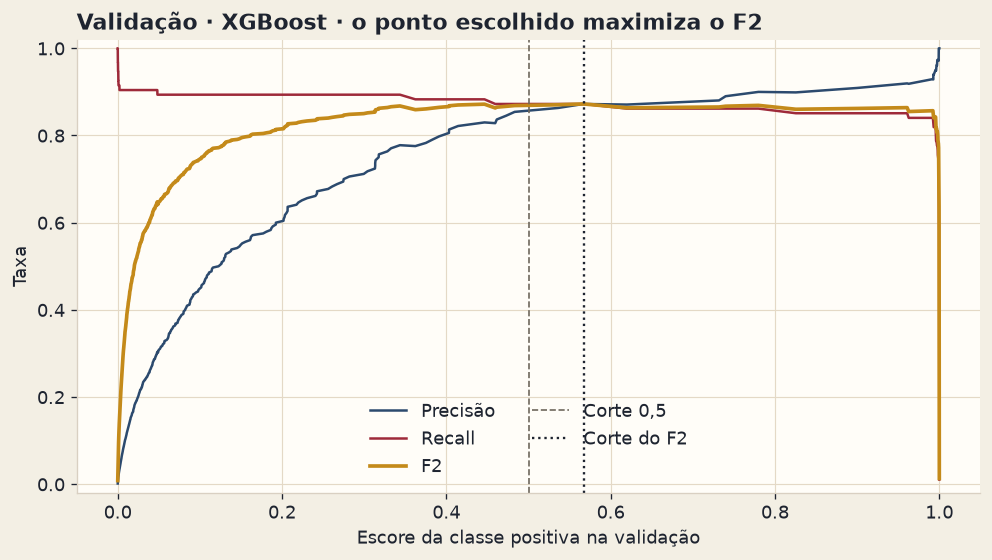

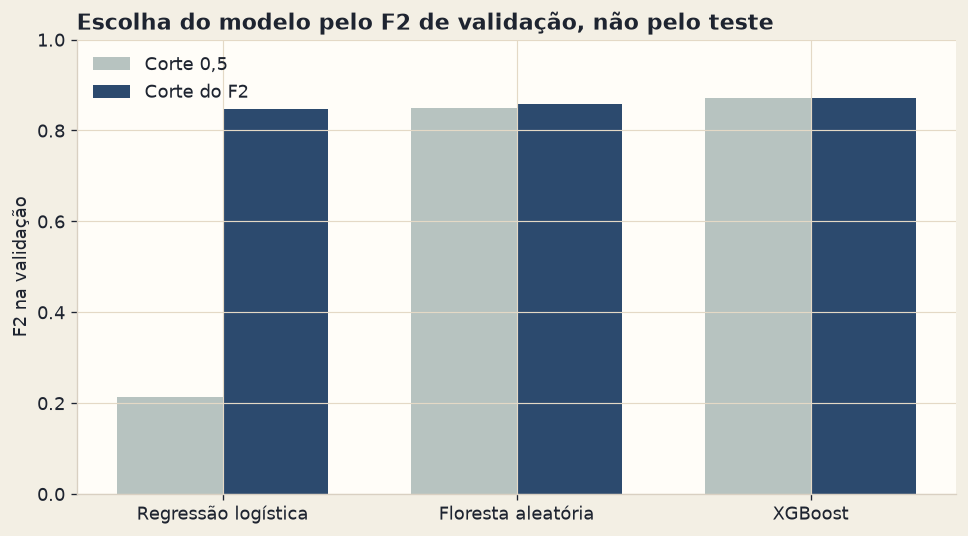

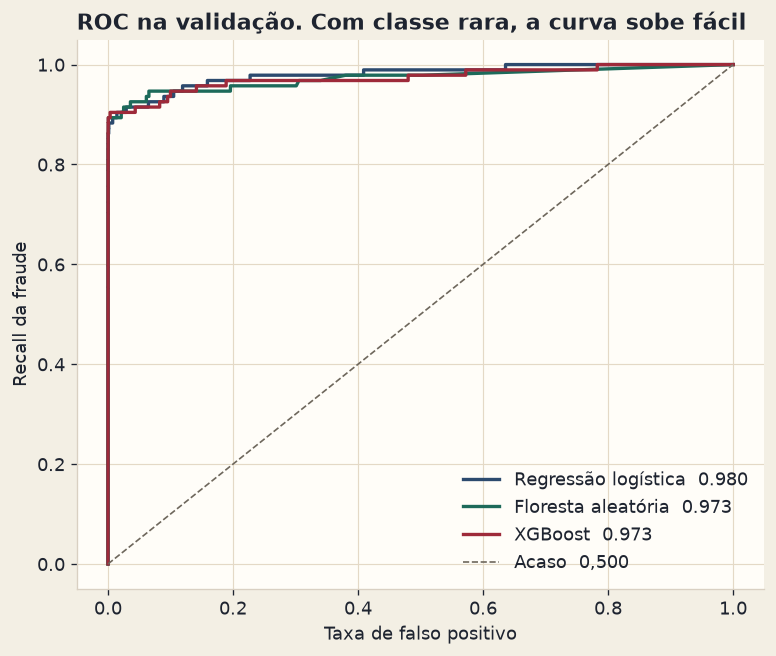

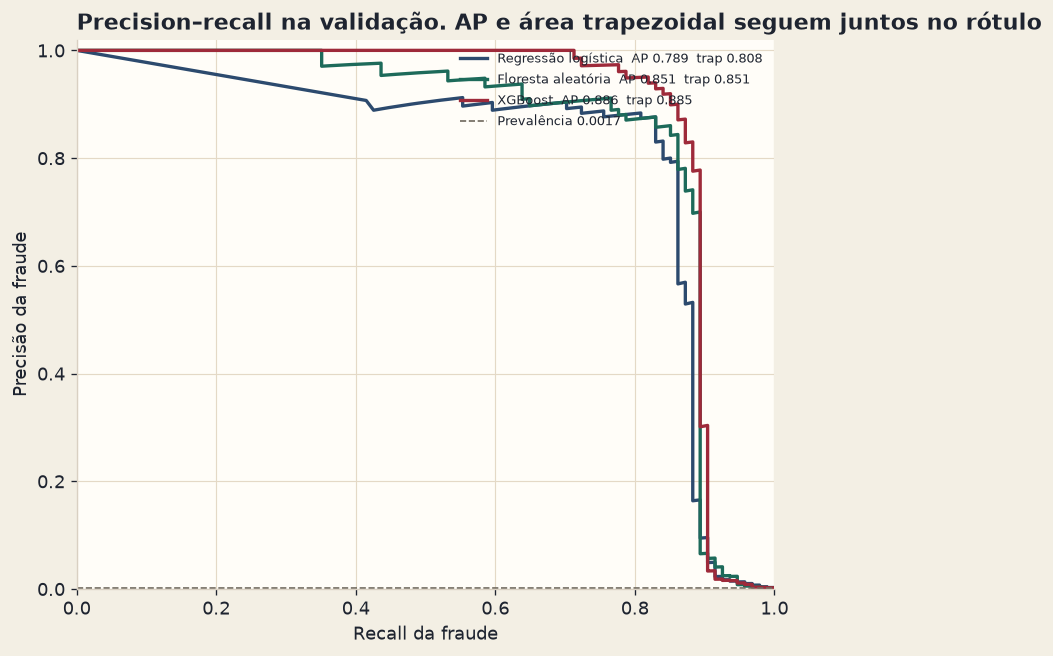

PosixPath('/workspace/artifacts/figuras/07_pr_validacao.png')

In [8]:
fig, ax = plt.subplots(figsize=(8.4, 4.8))
curva = varrer_limiares(y_validacao, escores_validacao[escolhido], beta=BETA_F)
ordem = np.argsort(curva["limiar"])
ax.plot(curva["limiar"][ordem], curva["precisao"][ordem], color=CORES["azul"], label="Precisão")
ax.plot(curva["limiar"][ordem], curva["recall"][ordem], color=CORES["fraude"], label="Recall")
ax.plot(curva["limiar"][ordem], curva["fbeta"][ordem], color=CORES["alerta"], lw=2.2, label="F2")
ax.axvline(0.5, color=CORES["apoio"], ls="--", lw=1, label="Corte 0,5")
ax.axvline(limiar_escolhido, color=CORES["tinta"], ls=":", lw=1.4, label="Corte do F2")
ax.set_xlabel("Escore da classe positiva na validação")
ax.set_ylabel("Taxa")
ax.set_ylim(-0.02, 1.02)
ax.set_title(f"Validação · {NOMES[escolhido]} · o ponto escolhido maximiza o F2", loc="left")
ax.legend(frameon=False, ncol=2)
salvar(fig, "04_limiar_f2_validacao.png")

fig, ax = plt.subplots(figsize=(8.2, 4.6))
posicoes = np.arange(len(CANDIDATOS))
largura = 0.36
f2_meio = [resultados[nome]["em_0_5"]["f2_fraude"] for nome in CANDIDATOS]
f2_corte = [resultados[nome]["no_limiar"]["f2_fraude"] for nome in CANDIDATOS]
ax.bar(posicoes - largura / 2, f2_meio, width=largura, color="#B7C3C0", label="Corte 0,5")
ax.bar(posicoes + largura / 2, f2_corte, width=largura, color=CORES["azul"], label="Corte do F2")
ax.set_xticks(posicoes, [NOMES[nome] for nome in CANDIDATOS])
ax.set_ylabel("F2 na validação")
ax.set_ylim(0, 1)
ax.set_title("Escolha do modelo pelo F2 de validação, não pelo teste", loc="left")
ax.legend(frameon=False)
salvar(fig, "05_f2_validacao.png")

fig, ax = plt.subplots(figsize=(6.6, 5.6))
for nome in CANDIDATOS:
    fpr, tpr, _ = roc_curve(y_validacao, escores_validacao[nome])
    auc_roc = resultados[nome]["no_limiar"]["roc_auc"]
    ax.plot(fpr, tpr, color=CORES_MODELO[nome], lw=2, label=f"{NOMES[nome]}  {auc_roc:.3f}")
ax.plot([0, 1], [0, 1], color=CORES["apoio"], ls="--", lw=1, label="Acaso  0,500")
ax.set_xlabel("Taxa de falso positivo")
ax.set_ylabel("Recall da fraude")
ax.set_title("ROC na validação. Com classe rara, a curva sobe fácil", loc="left")
ax.legend(frameon=False, loc="lower right")
salvar(fig, "06_roc_validacao.png")

fig, ax = plt.subplots(figsize=(6.8, 5.6))
prevalencia_val = float(y_validacao.mean())
for nome in CANDIDATOS:
    precisao, recall, _ = precision_recall_curve(y_validacao, escores_validacao[nome])
    bloco = resultados[nome]["no_limiar"]
    ax.plot(
        recall,
        precisao,
        color=CORES_MODELO[nome],
        lw=2,
        label=f"{NOMES[nome]}  AP {bloco['average_precision']:.3f}  trap {bloco['pr_auc_trapezio']:.3f}",
    )
ax.axhline(prevalencia_val, color=CORES["apoio"], ls="--", lw=1, label=f"Prevalência {prevalencia_val:.4f}")
ax.set_xlabel("Recall da fraude")
ax.set_ylabel("Precisão da fraude")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.set_title("Precision–recall na validação. AP e área trapezoidal seguem juntos no rótulo", loc="left")
ax.legend(frameon=False, loc="upper right", fontsize=8)
salvar(fig, "07_pr_validacao.png")


## Teste, uma leitura

O nome do modelo e o limiar já foram impressos na célula da validação. Esta célula só aplica esse par ao teste. Também registra o corte 0,5 do mesmo modelo e o dummy no corte 0,5. Os outros modelos não são reordenados pelo teste.

A average precision e a ROC AUC não dependem do limiar. Elas se repetem nas duas linhas do modelo escolhido. O que muda entre os cortes é precisão, recall, F2 e a carga de alertas.


In [9]:
escore_teste = escore_positivo(modelos[escolhido], X_teste)
teste_f2 = metricas_operacao(y_teste, escore_teste, limiar_escolhido, beta=BETA_F)
teste_05 = metricas_operacao(y_teste, escore_teste, 0.5, beta=BETA_F)
escore_dummy_teste = escore_positivo(modelos["dummy_sempre_legitima"], X_teste)
teste_dummy = metricas_operacao(y_teste, escore_dummy_teste, 0.5, beta=BETA_F)
predito_teste = (escore_teste >= limiar_escolhido).astype(np.int64)
relatorio_classes = classification_report(
    y_teste,
    predito_teste,
    target_names=["legitima_0", "fraude_1"],
    digits=4,
    zero_division=0,
    output_dict=True,
)
print(classification_report(
    y_teste,
    predito_teste,
    target_names=["legitima_0", "fraude_1"],
    digits=4,
    zero_division=0,
))

tabela_teste = pd.DataFrame(
    [
        {"modelo": NOMES[escolhido], "corte": "F2 travado", **{
            "limiar": teste_f2["limiar"],
            "precisao": teste_f2["precisao_fraude"],
            "recall": teste_f2["recall_fraude"],
            "f1": teste_f2["f1_fraude"],
            "f2": teste_f2["f2_fraude"],
            "AP": teste_f2["average_precision"],
            "PR_trapezio": teste_f2["pr_auc_trapezio"],
            "ROC_AUC": teste_f2["roc_auc"],
            "TP": teste_f2["tp"],
            "FP": teste_f2["fp"],
            "FN": teste_f2["fn"],
            "TN": teste_f2["tn"],
            "alertas_por_mil": teste_f2["alertas_por_mil"],
            "acuracia": teste_f2["acuracia"],
        }},
        {"modelo": NOMES[escolhido], "corte": "0,5", **{
            "limiar": teste_05["limiar"],
            "precisao": teste_05["precisao_fraude"],
            "recall": teste_05["recall_fraude"],
            "f1": teste_05["f1_fraude"],
            "f2": teste_05["f2_fraude"],
            "AP": teste_05["average_precision"],
            "PR_trapezio": teste_05["pr_auc_trapezio"],
            "ROC_AUC": teste_05["roc_auc"],
            "TP": teste_05["tp"],
            "FP": teste_05["fp"],
            "FN": teste_05["fn"],
            "TN": teste_05["tn"],
            "alertas_por_mil": teste_05["alertas_por_mil"],
            "acuracia": teste_05["acuracia"],
        }},
        {"modelo": NOMES["dummy_sempre_legitima"], "corte": "0,5", **{
            "limiar": teste_dummy["limiar"],
            "precisao": teste_dummy["precisao_fraude"],
            "recall": teste_dummy["recall_fraude"],
            "f1": teste_dummy["f1_fraude"],
            "f2": teste_dummy["f2_fraude"],
            "AP": teste_dummy["average_precision"],
            "PR_trapezio": teste_dummy["pr_auc_trapezio"],
            "ROC_AUC": teste_dummy["roc_auc"],
            "TP": teste_dummy["tp"],
            "FP": teste_dummy["fp"],
            "FN": teste_dummy["fn"],
            "TN": teste_dummy["tn"],
            "alertas_por_mil": teste_dummy["alertas_por_mil"],
            "acuracia": teste_dummy["acuracia"],
        }},
    ]
)
display(tabela_teste.round(4))
print(
    f"Teste · {NOMES[escolhido]} no limiar {limiar_escolhido:.6f}: "
    f"precisão {teste_f2['precisao_fraude']:.4f}, recall {teste_f2['recall_fraude']:.4f}, "
    f"F1 {teste_f2['f1_fraude']:.4f}, F2 {teste_f2['f2_fraude']:.4f}, "
    f"AP {teste_f2['average_precision']:.4f}, trapézio {teste_f2['pr_auc_trapezio']:.4f}, "
    f"ROC AUC {teste_f2['roc_auc']:.4f}."
)
print(
    f"Alertas {teste_f2['alertas']} ({teste_f2['alertas_por_mil']:.2f} por mil). "
    f"Falsos positivos {teste_f2['fp']} ({teste_f2['falsos_positivos_por_mil']:.2f} por mil). "
    f"Fraudes perdidas {teste_f2['fn']}. Fraudes revistas {teste_f2['tp']}."
)
print(
    f"Dummy no teste: acurácia {teste_dummy['acuracia']:.6f}, "
    f"recall de fraude {teste_dummy['recall_fraude']:.4f}, "
    f"F2 {teste_dummy['f2_fraude']:.4f}."
)
print(
    "Diferença AP − trapézio no teste:",
    teste_f2["average_precision"] - teste_f2["pr_auc_trapezio"],
)


              precision    recall  f1-score   support

  legitima_0     0.9996    0.9998    0.9997     56651
    fraude_1     0.8523    0.7895    0.8197        95

    accuracy                         0.9994     56746
   macro avg     0.9260    0.8946    0.9097     56746
weighted avg     0.9994    0.9994    0.9994     56746



,modelo,corte,limiar,precisao,recall,f1,f2,AP,PR_trapezio,ROC_AUC,TP,FP,FN,TN,alertas_por_mil,acuracia
0,XGBoost,F2 travado,0.5671,0.8523,0.7895,0.8197,0.8013,0.8238,0.8236,0.9686,75,13,20,56638,1.5508,0.9994
1,XGBoost,"0,5",0.5000,0.8172,0.8000,0.8085,0.8034,0.8238,0.8236,0.9686,76,17,19,56634,1.6389,0.9994
2,Dummy sempre legítima,"0,5",0.5000,0.0000,0.0000,0.0000,0.0000,0.0017,0.5008,0.5000,0,0,95,56651,0.0000,0.9983


Teste · XGBoost no limiar 0.567120: precisão 0.8523, recall 0.7895, F1 0.8197, F2 0.8013, AP 0.8238, trapézio 0.8236, ROC AUC 0.9686.
Alertas 88 (1.55 por mil). Falsos positivos 13 (0.23 por mil). Fraudes perdidas 20. Fraudes revistas 75.
Dummy no teste: acurácia 0.998326, recall de fraude 0.0000, F2 0.0000.
Diferença AP − trapézio no teste: 0.00017372021212525013


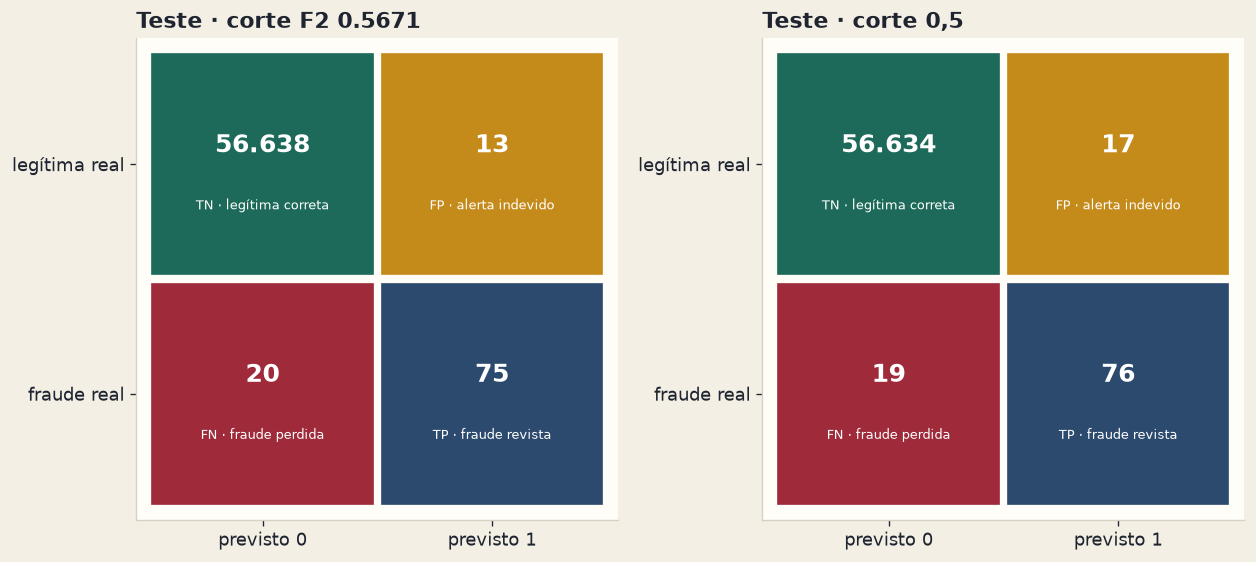

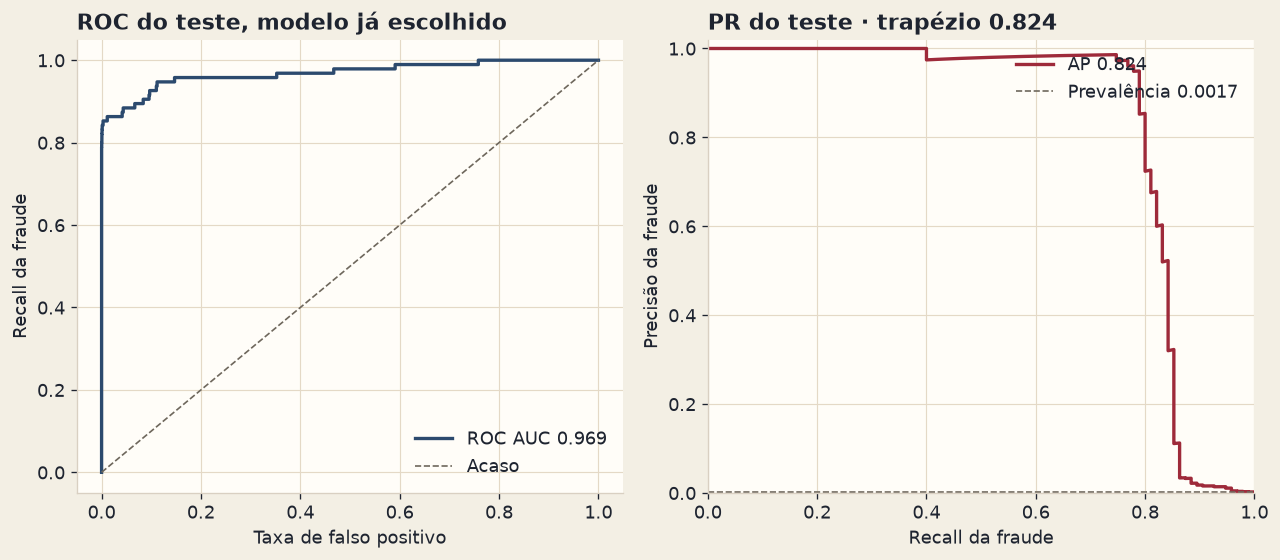

PosixPath('/workspace/artifacts/figuras/09_roc_pr_teste.png')

In [10]:
def desenhar_confusao(ax, bloco, titulo):
    ax.set_xlim(-0.55, 1.55)
    ax.set_ylim(-0.55, 1.55)
    ax.set_aspect("equal")
    ax.grid(False)
    celulas = [
        (0, 1, bloco["tn"], "TN · legítima correta", CORES["legitima"]),
        (1, 1, bloco["fp"], "FP · alerta indevido", CORES["alerta"]),
        (0, 0, bloco["fn"], "FN · fraude perdida", CORES["fraude"]),
        (1, 0, bloco["tp"], "TP · fraude revista", CORES["azul"]),
    ]
    for x, y, valor, texto, cor in celulas:
        ax.add_patch(Rectangle((x - 0.48, y - 0.48), 0.96, 0.96, color=cor))
        ax.text(x, y + 0.08, f"{valor:,}".replace(",", "."), ha="center", va="center", color="white", fontsize=15, fontweight="bold")
        ax.text(x, y - 0.18, texto, ha="center", va="center", color="white", fontsize=8)
    ax.set_xticks([0, 1], ["previsto 0", "previsto 1"])
    ax.set_yticks([0, 1], ["fraude real", "legítima real"])
    ax.set_title(titulo, loc="left")


fig, eixos = plt.subplots(1, 2, figsize=(10.6, 5.1))
desenhar_confusao(eixos[0], teste_f2, f"Teste · corte F2 {limiar_escolhido:.4f}")
desenhar_confusao(eixos[1], teste_05, "Teste · corte 0,5")
salvar(fig, "08_matriz_confusao_teste.png")

fig, eixos = plt.subplots(1, 2, figsize=(10.8, 4.8))
fpr, tpr, _ = roc_curve(y_teste, escore_teste)
eixos[0].plot(fpr, tpr, color=CORES["azul"], lw=2, label=f"ROC AUC {teste_f2['roc_auc']:.3f}")
eixos[0].plot([0, 1], [0, 1], color=CORES["apoio"], ls="--", lw=1, label="Acaso")
eixos[0].set_xlabel("Taxa de falso positivo")
eixos[0].set_ylabel("Recall da fraude")
eixos[0].set_title("ROC do teste, modelo já escolhido", loc="left")
eixos[0].legend(frameon=False, loc="lower right")
precisao, recall, _ = precision_recall_curve(y_teste, escore_teste)
eixos[1].plot(recall, precisao, color=CORES["fraude"], lw=2, label=f"AP {teste_f2['average_precision']:.3f}")
eixos[1].axhline(float(y_teste.mean()), color=CORES["apoio"], ls="--", lw=1, label=f"Prevalência {float(y_teste.mean()):.4f}")
eixos[1].set_xlabel("Recall da fraude")
eixos[1].set_ylabel("Precisão da fraude")
eixos[1].set_xlim(0, 1)
eixos[1].set_ylim(0, 1.02)
eixos[1].set_title(f"PR do teste · trapézio {teste_f2['pr_auc_trapezio']:.3f}", loc="left")
eixos[1].legend(frameon=False, loc="upper right")
salvar(fig, "09_roc_pr_teste.png")


## Explicação: importância global e SHAP

Se a validação escolheu uma árvore, o TreeSHAP explica esse modelo. Se escolheu a logística, os coeficientes explicam a logística, e o TreeSHAP fica no melhor árvore da validação, marcado como comparação.

A amostra global sai da validação, com semente 42: todas as fraudes dessa partição e 1.500 legítimas. A fraude fica sobrerrepresentada para o gráfico conseguir mostrá-la. A média do |SHAP| nessa mistura não é a média de uma transação típica da produção. Por isso o gráfico também separa a média dentro das fraudes e dentro das legítimas da amostra. Nada disso altera modelo nem limiar.

Os casos locais saem do teste, depois da métrica. A regra, fixada antes de olhar o caso, é: dentro de cada grupo (verdadeiro positivo, falso positivo, falso negativo), a transação cujo escore está mais perto da mediana do grupo. Empate fica com o menor índice. Grupo vazio não gera exemplo.

Os nomes no gráfico são os atributos que o modelo recebeu. `Amount_log1p_z` é o valor depois de `log1p` e da padronização do treino. O valor original em unidades monetárias aparece só no texto, como contexto. O espaço de saída do SHAP é conferido numericamente contra `predict_proba`: ou a soma fecha na probabilidade da classe 1, ou fecha no log-odds antes da sigmoide. O valor-base é o ponto de partida dessa soma.


SHAP de XGBoost (modelo escolhido na validação). Amostra de validação: 1594 linhas, 94 fraudes e 1500 legítimas.
TreeSHAP global em 0.0s | formato (1594, 30)
Espaço conferido: log_odds_antes_da_sigmoide. Erro máximo 4.026e-07.
Valor-base médio na amostra: 2.469699.


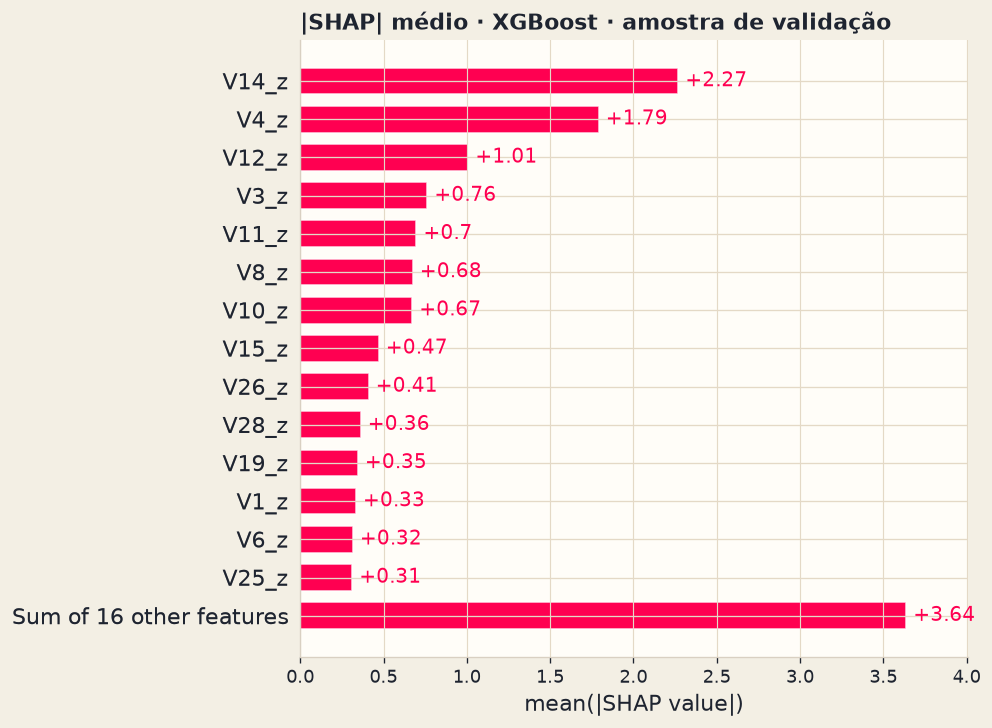

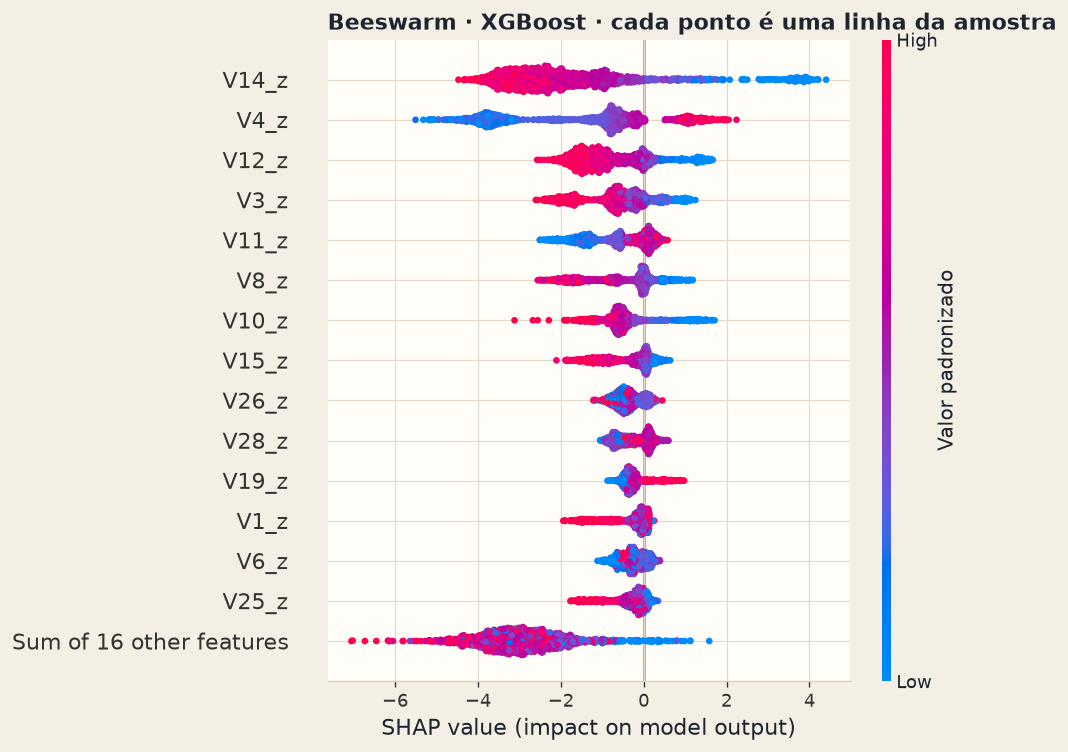

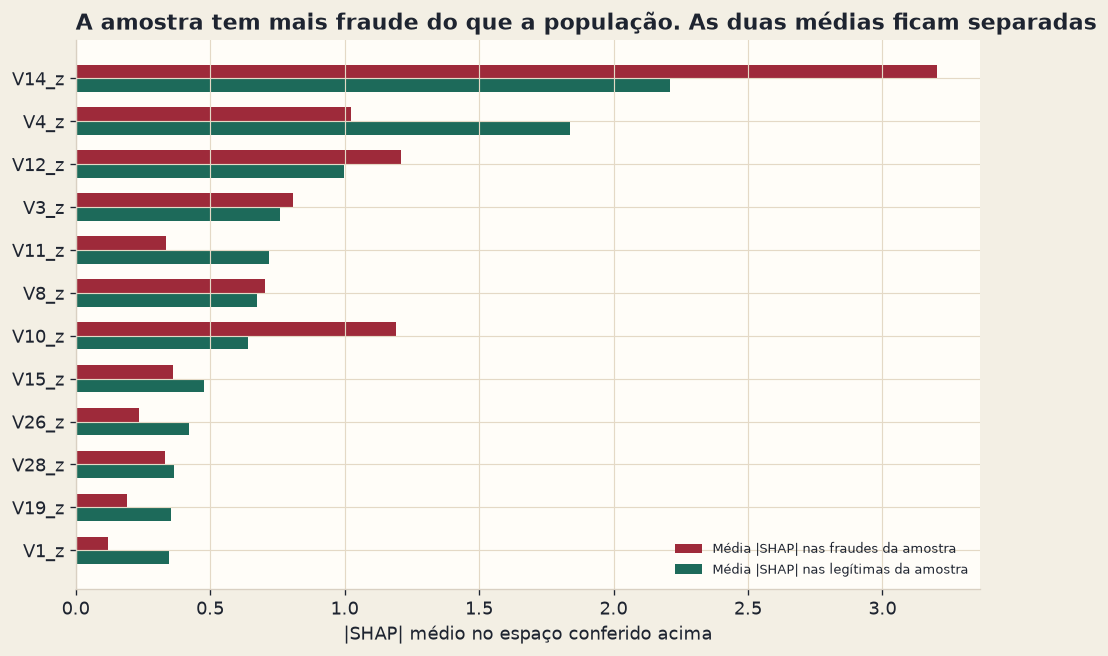

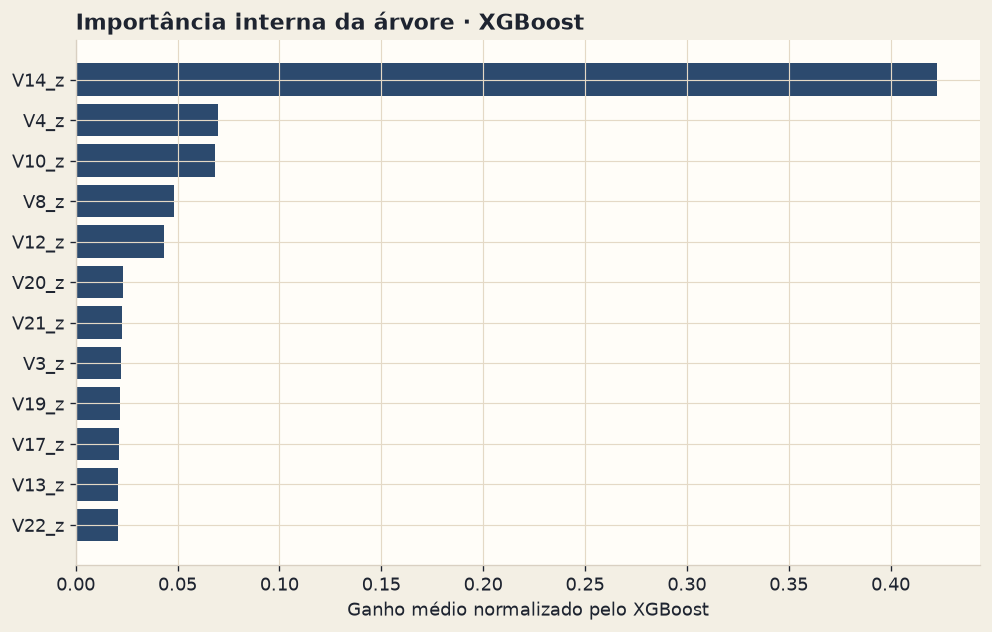

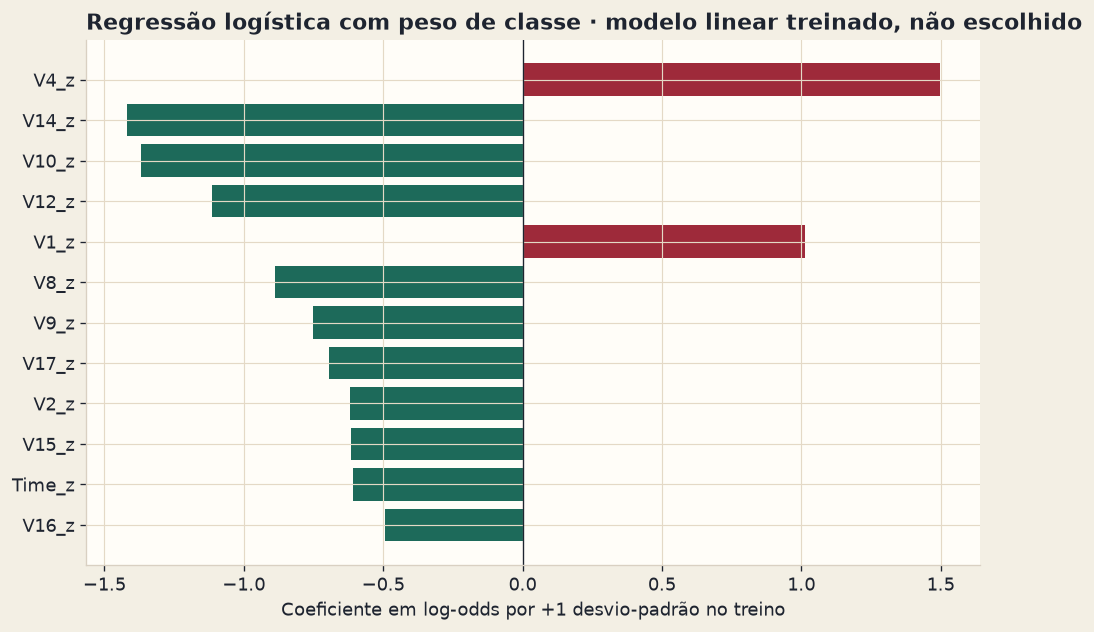

PosixPath('/workspace/artifacts/figuras/14_coeficientes_logistica.png')

In [11]:
def extrair_classe_positiva(explicacao_bruta):
    valores = np.asarray(explicacao_bruta.values, dtype=float)
    base = np.asarray(explicacao_bruta.base_values, dtype=float)
    if valores.ndim == 3:
        valores = valores[:, :, 1]
        base = base[:, 1] if base.ndim == 2 else np.full(valores.shape[0], float(base[1]))
    if base.ndim == 0:
        base = np.full(valores.shape[0], float(base))
    return valores, base


def identificar_espaco(saida, proba):
    erro_probabilidade = float(np.max(np.abs(saida - proba)))
    erro_log_odds = float(np.max(np.abs(expit(saida) - proba)))
    if erro_probabilidade <= 1e-3:
        return "probabilidade_classe_1", erro_probabilidade
    if erro_log_odds <= 1e-3:
        return "log_odds_antes_da_sigmoide", erro_log_odds
    raise RuntimeError(
        "O espaço do SHAP não fechou com a probabilidade do modelo: "
        f"erro direto {erro_probabilidade:.3e}, erro após sigmoide {erro_log_odds:.3e}"
    )


arvores = ["floresta_aleatoria", "xgboost"]
if escolhido in arvores:
    nome_shap = escolhido
    papel_shap = "modelo escolhido na validação"
else:
    nome_shap = max(arvores, key=chave_validacao)
    papel_shap = "modelo de comparação; a decisão da validação foi a regressão logística"

modelo_shap = modelos[nome_shap]
posicoes = amostra_explicacao(y_validacao, n_normais=1500, semente=SEMENTE)
X_amostra = X_validacao.iloc[posicoes]
y_amostra = y_validacao[posicoes]
print(
    f"SHAP de {NOMES[nome_shap]} ({papel_shap}). "
    f"Amostra de validação: {len(posicoes)} linhas, "
    f"{int((y_amostra == 1).sum())} fraudes e {int((y_amostra == 0).sum())} legítimas."
)

t0 = time.perf_counter()
explainer = shap.TreeExplainer(modelo_shap)
valores, base = extrair_classe_positiva(explainer(X_amostra))
print(f"TreeSHAP global em {time.perf_counter() - t0:.1f}s | formato {valores.shape}")
saida = base + valores.sum(axis=1)
proba_amostra = escore_positivo(modelo_shap, X_amostra)
espaco_shap, erro_espaco = identificar_espaco(saida, proba_amostra)
print(f"Espaço conferido: {espaco_shap}. Erro máximo {erro_espaco:.3e}.")
print(f"Valor-base médio na amostra: {float(np.mean(base)):.6f}.")

explicacao = shap.Explanation(
    values=valores,
    base_values=base,
    data=X_amostra.to_numpy(dtype=float),
    feature_names=list(X_amostra.columns),
)

shap.plots.bar(explicacao, max_display=15, show=False)
plt.gca().set_title(f"|SHAP| médio · {NOMES[nome_shap]} · amostra de validação", loc="left")
fig = plt.gcf()
fig.set_size_inches(8.4, 6.2)
salvar(fig, "10_shap_barra.png")

shap.plots.beeswarm(
    explicacao,
    max_display=15,
    show=False,
    plot_size=(8.4, 6.4),
    color_bar_label="Valor padronizado",
)
plt.gca().set_title(f"Beeswarm · {NOMES[nome_shap]} · cada ponto é uma linha da amostra", loc="left")
salvar(plt.gcf(), "11_shap_beeswarm.png")

media_abs = np.abs(valores).mean(axis=0)
media_fraude = np.abs(valores[y_amostra == 1]).mean(axis=0)
media_legitima = np.abs(valores[y_amostra == 0]).mean(axis=0)
ordem_imp = np.argsort(media_abs)[::-1][:12]
fig, ax = plt.subplots(figsize=(8.4, 5.6))
ypos = np.arange(len(ordem_imp))
ax.barh(ypos + 0.16, media_fraude[ordem_imp][::-1], height=0.32, color=CORES["fraude"], label="Média |SHAP| nas fraudes da amostra")
ax.barh(ypos - 0.16, media_legitima[ordem_imp][::-1], height=0.32, color=CORES["legitima"], label="Média |SHAP| nas legítimas da amostra")
ax.set_yticks(ypos, np.array(X_amostra.columns)[ordem_imp][::-1])
ax.set_xlabel("|SHAP| médio no espaço conferido acima")
ax.set_title("A amostra tem mais fraude do que a população. As duas médias ficam separadas", loc="left")
ax.legend(frameon=False, fontsize=8)
salvar(fig, "12_shap_por_classe.png")

importancias = np.asarray(modelo_shap.feature_importances_, dtype=float)
legenda_imp = (
    "Ganho médio normalizado pelo XGBoost"
    if nome_shap == "xgboost"
    else "Redução média de impureza na floresta"
)
ordem_ganho = np.argsort(importancias)[::-1][:12]
fig, ax = plt.subplots(figsize=(8.4, 5.4))
ax.barh(
    np.array(X_treino.columns)[ordem_ganho][::-1],
    importancias[ordem_ganho][::-1],
    color=CORES["azul"],
)
ax.set_xlabel(legenda_imp)
ax.set_title(f"Importância interna da árvore · {NOMES[nome_shap]}", loc="left")
salvar(fig, "13_importancia_arvore.png")

coeficientes = modelos["regressao_logistica"].coef_.ravel()
ordem_coef = np.argsort(np.abs(coeficientes))[::-1][:12]
fig, ax = plt.subplots(figsize=(8.4, 5.4))
valores_coef = coeficientes[ordem_coef][::-1]
cores_coef = [CORES["fraude"] if valor > 0 else CORES["legitima"] for valor in valores_coef]
ax.barh(np.array(X_treino.columns)[ordem_coef][::-1], valores_coef, color=cores_coef)
ax.axvline(0, color=CORES["tinta"], lw=0.8)
ax.set_xlabel("Coeficiente em log-odds por +1 desvio-padrão no treino")
papel_lr = "modelo escolhido" if escolhido == "regressao_logistica" else "modelo linear treinado, não escolhido"
ax.set_title(f"Regressão logística com peso de classe · {papel_lr}", loc="left")
salvar(fig, "14_coeficientes_logistica.png")


Regra local: escore mais próximo da mediana do grupo, desempate no menor índice.
Índices no teste, depois da métrica: {'tp': 2146, 'fp': 4051, 'fn': 22495}
Casos locais no mesmo espaço. Erro máximo 5.974e-08.
verdadeiro positivo: índice 2146, classe real 1, escore do modelo escolhido 0.9998, Amount original 0.00, base 2.4697, saída SHAP 8.6771.
  Atributo no modelo | valor transformado | SHAP
  V14_z               -11.005    3.580
  V4_z                  4.035    1.153
  V12_z                -4.574    1.092
  V10_z                -3.782    1.053
  V3_z                 -3.998    0.914
  V7_z                 -0.655    0.478
  V16_z                 0.234   -0.362
  Amount_log1p_z       -1.905    0.353


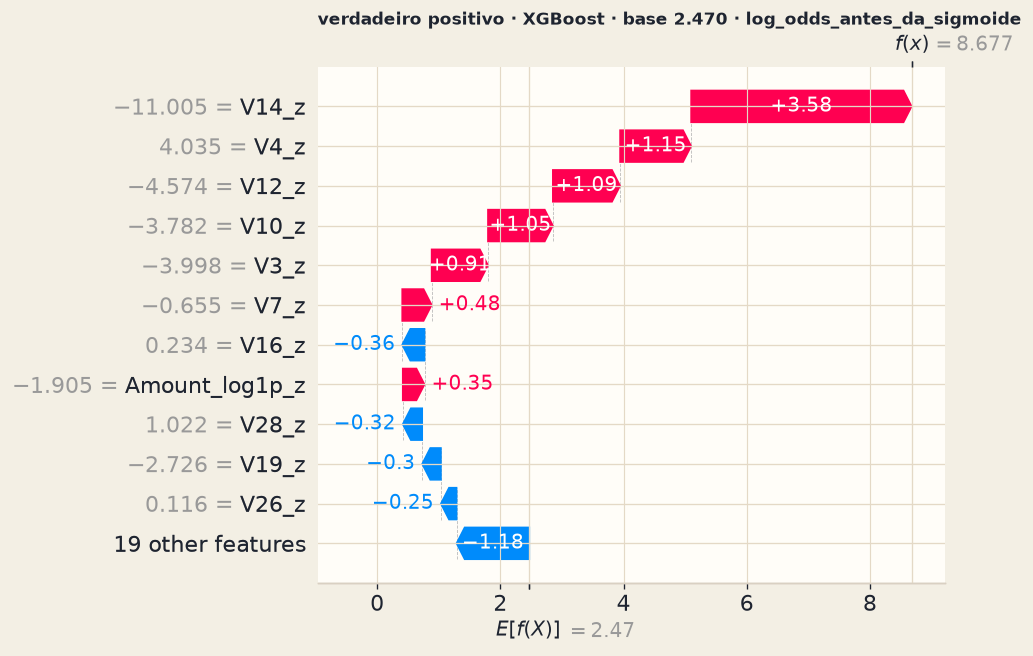

falso positivo: índice 4051, classe real 0, escore do modelo escolhido 0.6587, Amount original 10.61, base 2.4697, saída SHAP 0.6573.
  Atributo no modelo | valor transformado | SHAP
  V14_z                -7.068    2.952
  V7_z                  1.649   -1.993
  V16_z                 3.905   -0.998
  V10_z                -2.115    0.930
  V12_z                -3.030    0.880
  V4_z                  2.526    0.862
  V25_z                 0.173   -0.626
  V23_z                -0.755   -0.513


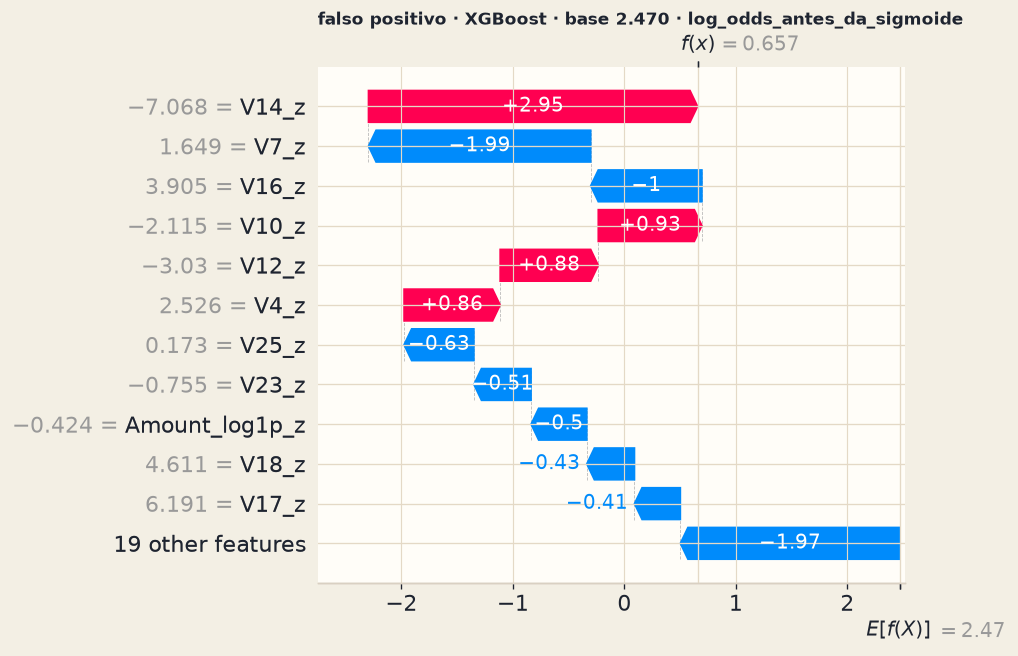

falso negativo: índice 22495, classe real 1, escore do modelo escolhido 0.0012, Amount original 105.99, base 2.4697, saída SHAP -6.7623.
  Atributo no modelo | valor transformado | SHAP
  V11_z                -0.964   -1.790
  V17_z                 1.342   -0.769
  V8_z                  0.125   -0.738
  V24_z                -1.560   -0.719
  V10_z                -0.736   -0.675
  V13_z                -1.112   -0.630
  V26_z                -0.942   -0.547
  V15_z                 0.443   -0.539


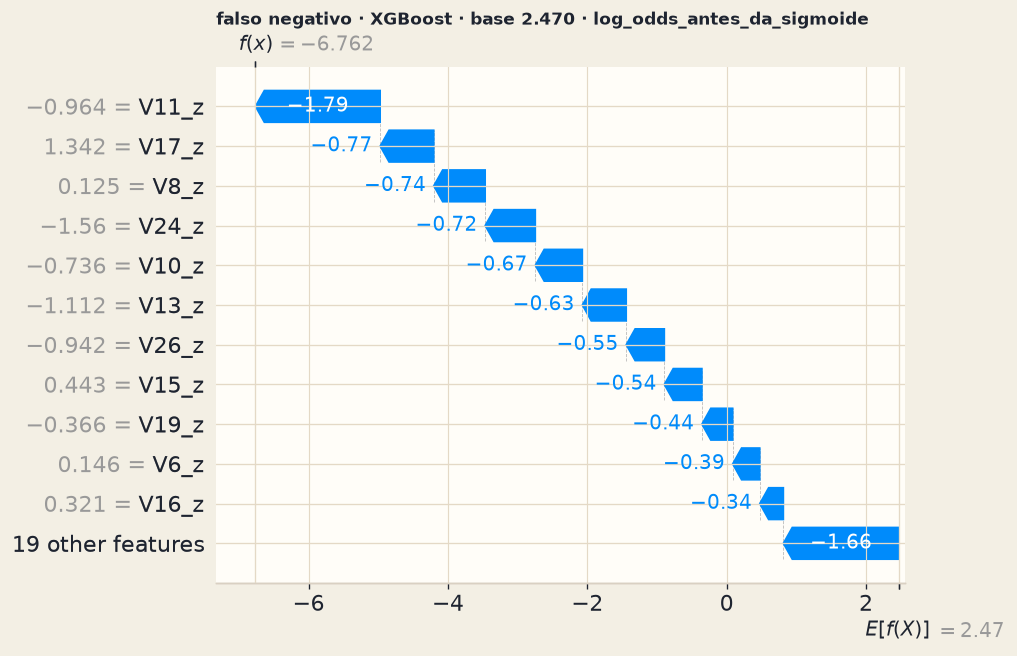

In [12]:
ROTULOS_CASO = {
    "tp": "verdadeiro positivo",
    "fp": "falso positivo",
    "fn": "falso negativo",
}
casos = {
    tipo: indice_representativo(y_teste, escore_teste, limiar_escolhido, tipo)
    for tipo in ("tp", "fp", "fn")
}
print("Regra local: escore mais próximo da mediana do grupo, desempate no menor índice.")
print("Índices no teste, depois da métrica:", casos)

lista = [(tipo, indice) for tipo, indice in casos.items() if indice is not None]
if not lista:
    raise RuntimeError("Nenhum caso local disponível para explicar.")
X_local = X_teste.iloc[[indice for _, indice in lista]]
valores_locais, base_local = extrair_classe_positiva(explainer(X_local))
saida_local = base_local + valores_locais.sum(axis=1)
proba_local = escore_positivo(modelo_shap, X_local)
_, erro_local = identificar_espaco(saida_local, proba_local)
print(f"Casos locais no mesmo espaço. Erro máximo {erro_local:.3e}.")

explicacao_local = shap.Explanation(
    values=valores_locais,
    base_values=base_local,
    data=X_local.to_numpy(dtype=float),
    feature_names=list(X_local.columns),
)

explicacoes = []
for ordem_caso, (tipo, indice) in enumerate(lista):
    contribuicoes = []
    ordem_abs = np.argsort(-np.abs(valores_locais[ordem_caso]))[:8]
    for coluna in ordem_abs:
        contribuicoes.append(
            {
                "atributo": str(X_local.columns[coluna]),
                "valor_transformado": float(X_local.iloc[ordem_caso, coluna]),
                "shap": float(valores_locais[ordem_caso, coluna]),
            }
        )
    registro = {
        "tipo": ROTULOS_CASO[tipo],
        "codigo": tipo,
        "indice_no_teste": int(indice),
        "classe_real": int(y_teste[indice]),
        "escore_do_modelo_escolhido": float(escore_teste[indice]),
        "limiar_do_modelo_escolhido": float(limiar_escolhido),
        "amount_original_contexto": float(ctx_teste.loc[indice, "Amount"]),
        "time_original_contexto": float(ctx_teste.loc[indice, "Time"]),
        "modelo_explicado": nome_shap,
        "papel_do_modelo_explicado": papel_shap,
        "espaco": espaco_shap,
        "valor_base": float(base_local[ordem_caso]),
        "saida_shap": float(saida_local[ordem_caso]),
        "probabilidade_ou_escore_do_modelo_explicado": float(proba_local[ordem_caso]),
        "maiores_contribuicoes": contribuicoes,
    }
    explicacoes.append(registro)
    print(
        f"{registro['tipo']}: índice {indice}, classe real {registro['classe_real']}, "
        f"escore do modelo escolhido {registro['escore_do_modelo_escolhido']:.4f}, "
        f"Amount original {registro['amount_original_contexto']:.2f}, "
        f"base {registro['valor_base']:.4f}, saída SHAP {registro['saida_shap']:.4f}."
    )
    print("  Atributo no modelo | valor transformado | SHAP")
    for item in contribuicoes:
        print(f"  {item['atributo']:18} {item['valor_transformado']:8.3f} {item['shap']:8.3f}")

    shap.plots.waterfall(explicacao_local[ordem_caso], max_display=12, show=False)
    plt.gca().set_title(
        f"{registro['tipo']} · {NOMES[nome_shap]} · base {registro['valor_base']:.3f} · {espaco_shap}",
        loc="left",
        fontsize=10,
    )
    fig = plt.gcf()
    fig.set_size_inches(8.6, 5.6)
    salvar(fig, f"15_shap_waterfall_{tipo}.png")

assert "Amount_log1p_z" in list(X_local.columns)
assert all("Amount" != item["atributo"] for caso in explicacoes for item in caso["maiores_contribuicoes"])


## Limitações

`V1`–`V28` são componentes de PCA publicados assim pelos autores, por confidencialidade. A importância e o SHAP não recuperam idade, estabelecimento, país, renda ou qualquer traço pessoal. Um coeficiente grande num `V12_z` é uma associação com o escore deste modelo, nestes atributos transformados.

O SHAP de árvore decompõe a saída do modelo. Associação com o escore não é causa da fraude e não é prova de fraude. O caso local ilustra uma transação já rotulada; a escolha do exemplo usou o rótulo só para dizer se o acerto foi positivo, falso positivo ou falso negativo, depois da métrica, e não para tunar o corte.

O peso de classe muda a perda de treino. O escore resultante ordena alertas. Ele não é uma probabilidade calibrada, e o valor-base do SHAP segue o espaço conferido na execução, não uma chance de fraude no mundo.

A avaliação é histórica, estratificada e IID. Sem identificador de cliente, este arquivo não sustenta feature de sequência comportamental. Um corte temporal seria outra pergunta e não foi usado como segundo teste. A validação escolheu modelo e limiar no mesmo bloco de linhas, então o F2 de validação é um pouco otimista. O teste, lido uma vez, é a estimativa reservada. Com cerca de cem fraudes no teste, a precisão e o recall ainda variam se a semente mudar.

Não houve dado sensível de cartão ou de pagamento. O material é o dataset público anonimizado.


In [13]:
def ranking(nomes_colunas, vetor, k=12):
    ordem = np.argsort(np.asarray(vetor))[::-1][:k]
    return [
        {"atributo": str(nomes_colunas[i]), "valor": float(vetor[i])}
        for i in ordem
    ]


resumo = {
    "versoes": versoes,
    "arquivo": {k: v for k, v in relatorio_arquivo.items() if k != "nomes"},
    "fingerprints": {
        "sha256_arquivo_bruto": SHA256_ARQUIVO_PUBLICO,
        "sha256_tabela_carregada": fp_tabela_bruta,
        "sha256_tabela_sem_duplicata_exata": fp_tabela_limpa,
        "linhas_brutas": relatorio["linhas_brutas"],
        "linhas_sem_duplicata_exata": relatorio["linhas_apos_remocao"],
    },
    "limpeza_e_split": relatorio,
    "scaler_amostras_vistas": int(scaler.n_samples_seen_),
    "scale_pos_weight_treino": peso_positivo,
    "hiperparametros": HIPER,
    "validacao": resultados,
    "regra_de_escolha": "maior F2 de validação no limiar que maximiza o F2; desempate por average precision e depois ROC AUC",
    "modelo_escolhido": escolhido,
    "limiar_escolhido": limiar_escolhido,
    "teste": {
        "modelo": escolhido,
        "corte_f2": teste_f2,
        "corte_0_5": teste_05,
        "dummy_corte_0_5": teste_dummy,
        "classification_report": relatorio_classes,
    },
    "shap": {
        "modelo": nome_shap,
        "papel": papel_shap,
        "espaco": espaco_shap,
        "erro_maximo_espaco": erro_espaco,
        "valor_base_medio_amostra": float(np.mean(base)),
        "amostra_validacao": {
            "n": int(len(y_amostra)),
            "fraudes": int((y_amostra == 1).sum()),
            "legitimas": int((y_amostra == 0).sum()),
            "n_normais_pedidos": 1500,
            "semente": SEMENTE,
            "sobrerrepresenta_fraude": True,
        },
        "media_abs_amostra": ranking(list(X_amostra.columns), media_abs),
        "media_abs_fraudes_da_amostra": ranking(list(X_amostra.columns), media_fraude),
        "media_abs_legitimas_da_amostra": ranking(list(X_amostra.columns), media_legitima),
        "importancia_interna": ranking(list(X_treino.columns), importancias),
        "legenda_importancia_interna": legenda_imp,
        "coeficientes_logistica_abs": ranking(list(X_treino.columns), np.abs(coeficientes)),
        "casos_locais": explicacoes,
    },
}
destino = ROOT / "artifacts" / "metricas.json"
destino.write_text(json.dumps(jsonavel(resumo), ensure_ascii=False, indent=2), encoding="utf-8")
(ROOT / "artifacts" / "ambiente.json").write_text(
    json.dumps(jsonavel(versoes), ensure_ascii=False, indent=2),
    encoding="utf-8",
)
print("Métricas gravadas em", destino)
print("Figuras:")
for caminho in sorted(FIGURAS.glob("*.png")):
    print(f"  {caminho.name:32} {caminho.stat().st_size:8d} bytes")


Métricas gravadas em /workspace/artifacts/metricas.json
Figuras:
  01_desbalanceamento.png             41895 bytes
  02_amount_log1p.png                 37954 bytes
  03_fraude_por_hora.png              82117 bytes
  04_limiar_f2_validacao.png          80382 bytes
  05_f2_validacao.png                 40834 bytes
  06_roc_validacao.png                75988 bytes
  07_pr_validacao.png                 73483 bytes
  08_matriz_confusao_teste.png        72622 bytes
  09_roc_pr_teste.png                 95061 bytes
  10_shap_barra.png                   91853 bytes
  11_shap_beeswarm.png               182812 bytes
  12_shap_por_classe.png              57873 bytes
  13_importancia_arvore.png           52532 bytes
  14_coeficientes_logistica.png       53435 bytes
  15_shap_waterfall_fn.png           104573 bytes
  15_shap_waterfall_fp.png           103413 bytes
  15_shap_waterfall_tp.png           106103 bytes
